In [ ]:
# Cargar CSV desde Colab o local
import os
from google.colab import files

if not os.path.exists('Transacciones_de_ventas Practica.csv'):
    print("Sube el archivo CSV:")
    uploaded = files.upload()
    print("Archivo cargado correctamente.")
else:
    print("Archivo ya existe.")


# Minería de Datos - Práctica 3.1 Agrupación (Clustering)
## Equipo 7
**Integrantes:** Rafael Ortega de la Paz, Claudio Flores García, Barvara Caridad Juarez Valdivia

**Caso:** el archivo *Transacciones de Ventas* tiene 58,903 líneas de venta (producto por producto) de 524 clientes. Se agrupa a los clientes según sus hábitos de compra y gasto.

**Objetivo:** Segmentación de clientes basada en hábitos de consumo y gasto para campañas de marketing personalizadas.

**Algoritmos:** K-Means, DBSCAN, Hierarchical Clustering

**Técnica de reducción dimensional:** PCA (Principal Component Analysis)

## SECCIÓN 1: Carga, Exploración Inicial (EDA) y Limpieza de Datos

In [1]:
# Importar librerías necesarias
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans, DBSCAN, AgglomerativeClustering
from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score
import warnings
warnings.filterwarnings('ignore')

# Configurar visualizaciones
sns.set_style('whitegrid')
plt.rcParams['figure.figsize'] = (12, 6)

print("✓ Librerías importadas correctamente")

✓ Librerías importadas correctamente


In [2]:
# Cargar datos
# Busca el CSV en las ubicaciones habituales; en Colab permite subirlo si no está
import os, glob
rutas = ['/content/Transacciones_de_ventas Practica.csv', 'Transacciones_de_ventas Practica.csv',
         'Transacciones_de_ventas_Practica.csv', '/content/drive/MyDrive/Transacciones_de_ventas Practica.csv']
ruta = next((r for r in rutas if os.path.exists(r)), None)
if ruta is None:
    cand = glob.glob('/content/*.csv') + glob.glob('**/Transacciones*Practica*.csv', recursive=True)
    ruta = cand[0] if cand else None
if ruta is None:
    try:
        from google.colab import files
        print("Sube el archivo 'Transacciones_de_ventas Practica.csv'")
        ruta = list(files.upload().keys())[0]
    except ImportError:
        raise FileNotFoundError("Coloca el CSV en la misma carpeta que el notebook")
df = pd.read_csv(ruta, encoding='cp1252')
print(f"Archivo: {ruta}")

print(f"Forma del dataset: {df.shape}")
print(f"\nPrimeras 5 filas:")
print(df.head())

print(f"\nTipos de datos:")
print(df.dtypes)

print(f"\nValores faltantes por columna:")
print(df.isnull().sum())

Archivo: Transacciones_de_ventas Practica.csv
Forma del dataset: (58903, 33)

Primeras 5 filas:
  Sector     Tipo                Linea         Sublinea Presentacion  Gramaje  \
0  OTROS  PROLIVO  ACEITES  Y MANTECAS  ACEITE DE OLIVA   PAQUETERIA     2.29   
1  OTROS  PROLIVO  ACEITES  Y MANTECAS  ACEITE DE OLIVA   PAQUETERIA     2.29   
2  OTROS  PROLIVO  ACEITES  Y MANTECAS  ACEITE DE OLIVA   PAQUETERIA     2.29   
3  OTROS  PROLIVO  ACEITES  Y MANTECAS  ACEITE DE OLIVA   PAQUETERIA     2.29   
4  OTROS  PROLIVO  ACEITES  Y MANTECAS  ACEITE DE OLIVA   PAQUETERIA     2.29   

                             Empresa   Año     Fecha          Cliente  ...  \
0                  957936 ALFA TORRE  2015  04-12-15  126306 LAURA IS  ...   
1                  957936 ALFA TORRE  2016  14-01-16  206654 ROBERTO   ...   
2  303012 CORPORATIVO BETA COMERCIAL  2016  13-06-16  203171 LILIANA   ...   
3                  957936 ALFA TORRE  2016  14-06-16  220447 ADALILIA  ...   
4            436463 ALFA CA

**¿Qué hacemos aquí?** Revisamos tipos de dato, nulos y estadísticos básicos para detectar problemas (valores raros, columnas vacías) antes de agrupar. Recordemos que cada fila del CSV es una *línea de producto* dentro de una venta, no un cliente.

In [3]:
# Análisis descriptivo de variables numéricas
print("Estadísticas descriptivas:")
print(df.describe())

# Contar clientes únicos
num_clientes = df['Clave_Cliente'].nunique()
print(f"\nNúmero de clientes únicos: {num_clientes}")

# Variables categóricas
print(f"\nVariables categóricas únicas:")
for col in df.select_dtypes(include='object').columns:
    print(f"  {col}: {df[col].nunique()} valores únicos")

Estadísticas descriptivas:
            Gramaje           Año    Transaccion         Pedido       Control  \
count  58903.000000  58903.000000   58903.000000   58903.000000  5.890300e+04   
mean       0.422715   2015.094715  566993.296182   95670.198224  1.815129e+06   
std        0.523643      0.810848   13311.308168   13436.469024  1.111146e+07   
min        0.030000   2014.000000  542421.000000   70855.000000  1.200000e+01   
25%        0.200000   2014.000000  555513.000000   84080.000000  8.050000e+02   
50%        0.300000   2015.000000  567352.000000   96128.000000  7.446000e+03   
75%        0.450000   2016.000000  579254.000000  108005.000000  9.008000e+03   
max       15.800000   2016.000000  588519.000000  117442.000000  7.009002e+07   

           Producto      Cantidad        Precio    Precio_Max  Dif_PrecioMax  \
count  5.890300e+04  58903.000000  58903.000000  58903.000000   58903.000000   
mean   1.815129e+06      1.687656     40.852449     47.909220       7.056769   
std

**Limpieza:** eliminamos filas completamente duplicadas, porque inflarían artificialmente el gasto y el número de líneas de un cliente.

In [4]:
# Limpieza básica: eliminar duplicados si existen
df_limpio = df.drop_duplicates().copy()
print(f"Registros antes: {len(df)}, después: {len(df_limpio)}")

# Manejar valores faltantes (eliminar o imputar según corresponda)
df_limpio = df_limpio.dropna(subset=['Clave_Cliente', 'Importe', 'Cantidad'])
print(f"Registros después de eliminar nulos críticos: {len(df_limpio)}")

df = df_limpio

Registros antes: 58903, después: 58903
Registros después de eliminar nulos críticos: 58903


## SECCIÓN 2: Selección de Variables y Agregación por Cliente

**Agregación por cliente.** El clustering busca *segmentos de clientes*, no de líneas de venta; por eso resumimos las 58,903 líneas en **una fila por cliente** (524 clientes) con 8 variables de comportamiento y perfil.

In [5]:
# Crear tabla agregada por cliente
# Variables a construir para clustering

cliente_agg = df.groupby('Clave_Cliente').agg({
    'Importe': ['sum', 'mean', 'count'],  # Gasto total, importe promedio por línea, # de líneas de venta
    'Cantidad': 'mean',                    # Cantidad promedio por línea
    'Precio': 'mean',                      # Precio promedio
    'Antiguedad': 'first',                 # Antigüedad del cliente
    'Edad': 'first',                       # Edad del cliente
    'No._Hijos': 'first',                  # Número de hijos
}).reset_index()

# Simplificar nombres de columnas
cliente_agg.columns = ['Clave_Cliente', 'Gasto_Total', 'Ticket_Promedio', 'Num_Transacciones',
                       'Cantidad_Promedio', 'Precio_Promedio', 'Antiguedad', 'Edad', 'Num_Hijos']

print(f"Tabla agregada por cliente creada:")
print(f"Número de clientes únicos: {len(cliente_agg)}")
print(f"\nPrimeras 5 registros:")
print(cliente_agg.head())

print(f"\nEstadísticas de variables agregadas:")
print(cliente_agg.describe())

Tabla agregada por cliente creada:
Número de clientes únicos: 524

Primeras 5 registros:
   Clave_Cliente  Gasto_Total  Ticket_Promedio  Num_Transacciones  \
0         100167      6791.96        55.671803                122   
1         100263      6951.88        31.743744                219   
2         100363       373.50        33.954545                 11   
3         100491       328.00        46.857143                  7   
4         100861     12792.41        45.687179                280   

   Cantidad_Promedio  Precio_Promedio  Antiguedad  Edad  Num_Hijos  
0           2.049180        43.146475          15    35          0  
1           1.141553        30.553333          15    40          0  
2           1.272727        26.909091          15    35          2  
3           1.142857        38.357143          15    57          0  
4           1.478571        33.742179          15    41          0  

Estadísticas de variables agregadas:
       Clave_Cliente    Gasto_Total  Ticket_

In [6]:
# Seleccionar variables para clustering
# Excluir Clave_Cliente (identificador, no feature)
variables_clustering = ['Gasto_Total', 'Ticket_Promedio', 'Num_Transacciones',
                        'Cantidad_Promedio', 'Precio_Promedio', 'Antiguedad', 'Edad', 'Num_Hijos']

X = cliente_agg[variables_clustering].copy()

# Manejar valores faltantes en la tabla agregada
X = X.fillna(X.mean())

variables_sesgadas = ['Gasto_Total', 'Ticket_Promedio', 'Num_Transacciones', 'Cantidad_Promedio', 'Precio_Promedio']
X[variables_sesgadas] = np.log1p(X[variables_sesgadas])

print(f"Variables seleccionadas para clustering: {variables_clustering}")
print(f"Forma del conjunto de características: {X.shape}")
print(f"\nVerificar que no haya nulos:")
print(X.isnull().sum())

Variables seleccionadas para clustering: ['Gasto_Total', 'Ticket_Promedio', 'Num_Transacciones', 'Cantidad_Promedio', 'Precio_Promedio', 'Antiguedad', 'Edad', 'Num_Hijos']
Forma del conjunto de características: (524, 8)

Verificar que no haya nulos:
Gasto_Total          0
Ticket_Promedio      0
Num_Transacciones    0
Cantidad_Promedio    0
Precio_Promedio      0
Antiguedad           0
Edad                 0
Num_Hijos            0
dtype: int64


### Variables utilizadas y variables excluidas
- **Usadas (8):** Gasto_Total, Ticket_Promedio, Num_Transacciones, Cantidad_Promedio, Precio_Promedio, Antiguedad, Edad, Num_Hijos.
- **Excluidas:** `Clave_Cliente` (identificador); columnas de producto/catálogo (Sector, Tipo, Linea, Sublinea, Presentacion, Gramaje, Producto, Descripcion, Unidad) y de documento (Transaccion, Pedido, Control, Fecha, Año), porque describen *qué* y *cuándo* se vendió y no al cliente; `Precio_Max` y `Dif_PrecioMax` (derivadas del precio, redundantes con `Precio_Promedio`); y variables categóricas del cliente (Escolaridad, Estado_Civil, Estado, Sexo, Funcion, Grupo, Reg, Edad_Rango), que requerirían codificación y no son adecuadas para distancias euclidianas sin tratamiento adicional (`Edad_Rango` además repite a `Edad`).
- **Tamaño de la muestra:** el archivo contiene **524 clientes** (algo menos que el rango de ~800–1,000 mencionado en clase). Es suficiente para K-Means con k pequeño, pero conviene tenerlo en cuenta al interpretar la estabilidad de los clusters.

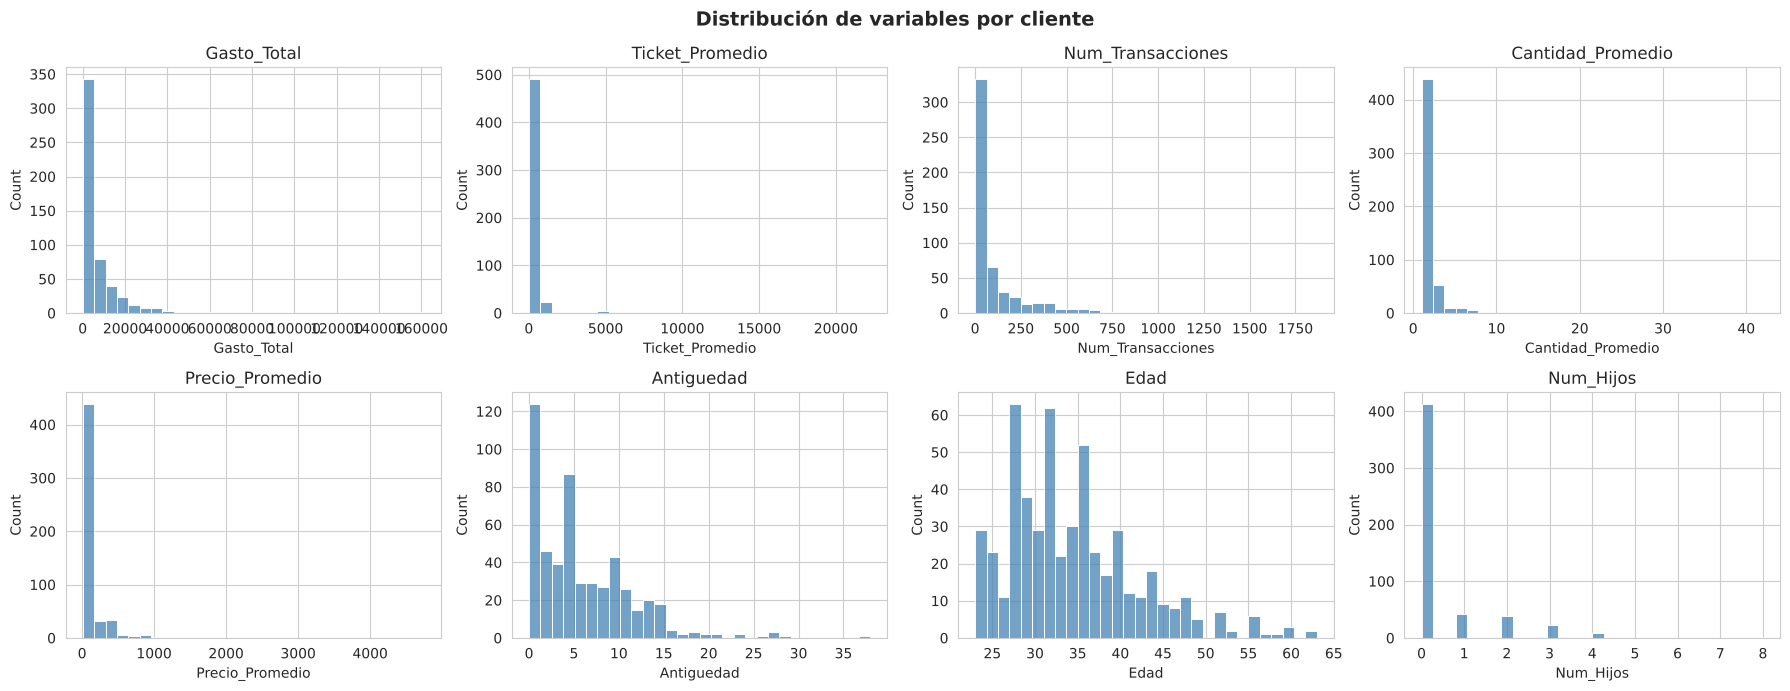

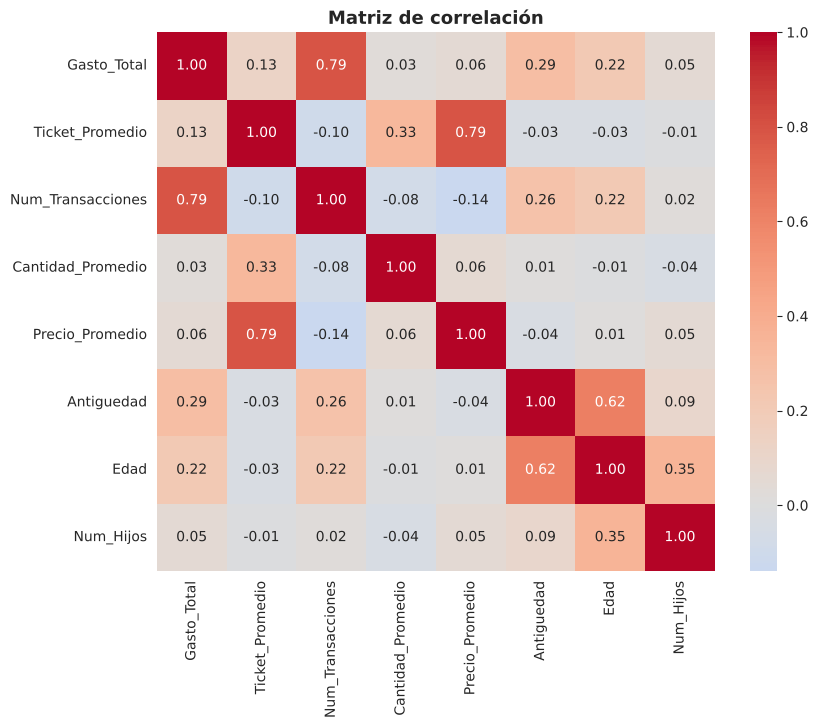

In [7]:
# Comportamiento de las variables por cliente
fig, axes = plt.subplots(2, 4, figsize=(18, 7))
for ax, v in zip(axes.ravel(), variables_clustering):
    sns.histplot(cliente_agg[v], bins=30, ax=ax, color='steelblue')
    ax.set_title(v)
plt.suptitle('Distribución de variables por cliente', fontsize=14, fontweight='bold')
plt.tight_layout(); plt.show()

plt.figure(figsize=(9, 7))
sns.heatmap(cliente_agg[variables_clustering].corr(), annot=True, fmt='.2f', cmap='coolwarm', center=0)
plt.title('Matriz de correlación', fontsize=13, fontweight='bold'); plt.show()

### Nota sobre la definición de las variables
Cada fila del CSV es una **línea de producto** dentro de una venta, no una compra completa. Por eso, en este análisis:
- `Num_Transacciones` = número de **líneas de venta** del cliente (promedio ~112; las transacciones únicas son ~22 por cliente).
- `Ticket_Promedio` = **importe promedio por línea** de venta.

Se conservan los nombres originales para que coincidan con el proceso de RapidMiner. En el **Anexo** se repite el análisis contando transacciones únicas y los segmentos resultan muy parecidos.

## SECCIÓN 3: Estandarización (StandardScaler) y Análisis PCA

**Estandarización.** K-Means, DBSCAN y el clustering jerárquico usan distancias; si una variable está en miles (Gasto) y otra en decenas (Edad), la primera dominaría. `StandardScaler` deja todas con media 0 y desviación 1.

In [8]:
# PASO 1: Estandarizar los datos (OBLIGATORIO)
scaler = StandardScaler()
X_escalado = scaler.fit_transform(X)

print("Datos escalados con StandardScaler:")
print(f"Media de cada variable: {X_escalado.mean(axis=0).round(4)}")
print(f"Desviación estándar de cada variable: {X_escalado.std(axis=0).round(4)}")

# Convertir a DataFrame para facilitar visualización
X_escalado_df = pd.DataFrame(X_escalado, columns=variables_clustering)

Datos escalados con StandardScaler:
Media de cada variable: [-0. -0. -0.  0.  0.  0. -0. -0.]
Desviación estándar de cada variable: [1. 1. 1. 1. 1. 1. 1. 1.]


**PCA (reducción dimensional).** Se usa para *entender* la estructura de las 8 variables y para poder graficar los clientes en 2D. Los algoritmos de clustering se entrenan sobre las 8 variables escaladas (el Anexo A muestra que usar PCA da casi la misma segmentación, ARI ≈ 0.91).

In [9]:
# PASO 2: Aplicar PCA para reducción dimensional
# Probar con todas las componentes primero
pca_full = PCA()
X_pca_full = pca_full.fit_transform(X_escalado)

# Calcular varianza explicada acumulada
varianza_explicada = pca_full.explained_variance_ratio_
varianza_acumulada = np.cumsum(varianza_explicada)

print("Varianza explicada por cada componente principal:")
for i, (var, var_acum) in enumerate(zip(varianza_explicada, varianza_acumulada), 1):
    print(f"PC{i}: {var:.4f} (Acumulada: {var_acum:.4f})")

Varianza explicada por cada componente principal:
PC1: 0.3240 (Acumulada: 0.3240)
PC2: 0.2470 (Acumulada: 0.5710)
PC3: 0.1770 (Acumulada: 0.7480)
PC4: 0.1098 (Acumulada: 0.8577)
PC5: 0.0988 (Acumulada: 0.9566)
PC6: 0.0402 (Acumulada: 0.9968)
PC7: 0.0029 (Acumulada: 0.9998)
PC8: 0.0002 (Acumulada: 1.0000)


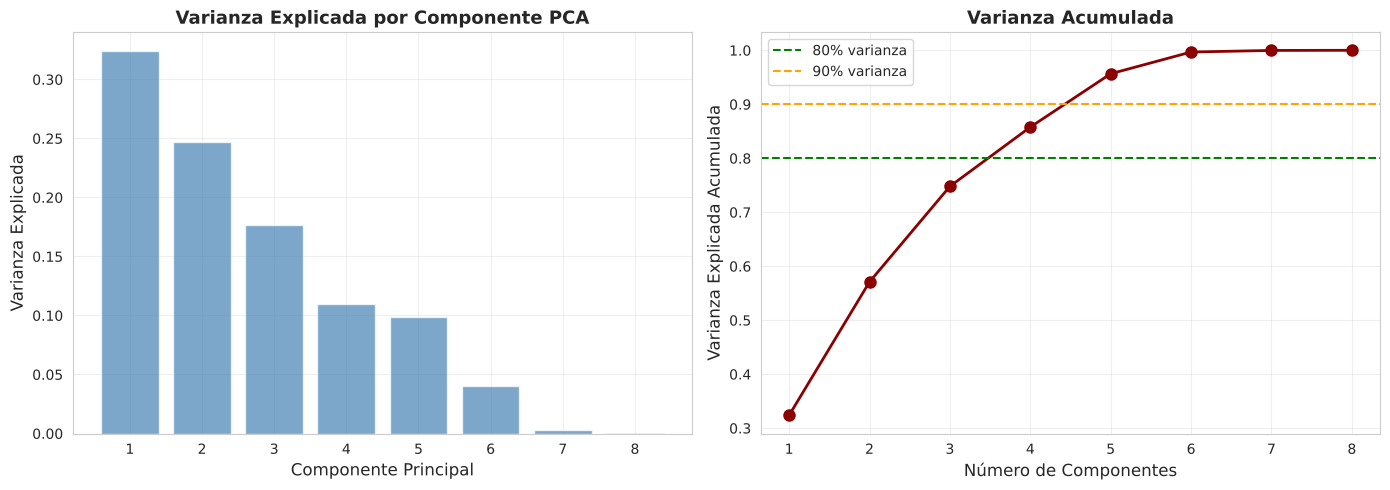


✓ Gráfica 1 generada: Análisis PCA


In [10]:
# Gráfica 1: Varianza explicada acumulada
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Varianza individual
ax1.bar(range(1, len(varianza_explicada) + 1), varianza_explicada, alpha=0.7, color='steelblue')
ax1.set_xlabel('Componente Principal', fontsize=12)
ax1.set_ylabel('Varianza Explicada', fontsize=12)
ax1.set_title('Varianza Explicada por Componente PCA', fontsize=13, fontweight='bold')
ax1.grid(True, alpha=0.3)

# Varianza acumulada
ax2.plot(range(1, len(varianza_acumulada) + 1), varianza_acumulada, 'o-', linewidth=2, markersize=8, color='darkred')
ax2.axhline(y=0.8, color='green', linestyle='--', label='80% varianza')
ax2.axhline(y=0.9, color='orange', linestyle='--', label='90% varianza')
ax2.set_xlabel('Número de Componentes', fontsize=12)
ax2.set_ylabel('Varianza Explicada Acumulada', fontsize=12)
ax2.set_title('Varianza Acumulada', fontsize=13, fontweight='bold')
ax2.legend()
ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

print("\n✓ Gráfica 1 generada: Análisis PCA")

In [11]:
# Determinar número óptimo de componentes (e.g., 80% varianza)
n_componentes_80 = np.argmax(varianza_acumulada >= 0.80) + 1
print(f"Componentes necesarios para 80% de varianza: {n_componentes_80}")

# Usar 3 componentes principales para el análisis (ajustar si es necesario)
n_componentes = min(3, n_componentes_80)
pca = PCA(n_components=n_componentes)
X_pca = pca.fit_transform(X_escalado)

print(f"\nUsando {n_componentes} componentes principales")
print(f"Varianza acumulada explicada: {pca.explained_variance_ratio_.sum():.4f}")

Componentes necesarios para 80% de varianza: 4

Usando 3 componentes principales
Varianza acumulada explicada: 0.7480


In [12]:
# Análisis de componentes: qué variables son más importantes en cada PC
print("\n" + "="*80)
print("INTERPRETACIÓN DE COMPONENTES PRINCIPALES")
print("="*80)

loadings = pca.components_.T * np.sqrt(pca.explained_variance_)
loadings_df = pd.DataFrame(
    loadings,
    columns=[f'PC{i+1}' for i in range(n_componentes)],
    index=variables_clustering
)

print("\nCargas (loadings) de variables en cada componente:")
print(loadings_df.round(4))

for i in range(n_componentes):
    print(f"\nPC{i+1} (Varianza: {pca.explained_variance_ratio_[i]:.2%}):")
    top_vars = loadings_df[f'PC{i+1}'].abs().nlargest(3)
    for var, carga in top_vars.items():
        print(f"  {var}: {carga:.4f}")


INTERPRETACIÓN DE COMPONENTES PRINCIPALES

Cargas (loadings) de variables en cada componente:
                      PC1     PC2     PC3
Gasto_Total        0.4568  0.5811 -0.5823
Ticket_Promedio   -0.8300  0.4760 -0.2564
Num_Transacciones  0.8903  0.2007 -0.3300
Cantidad_Promedio -0.2875  0.3867 -0.3945
Precio_Promedio   -0.8126  0.3710 -0.1172
Antiguedad         0.3311  0.6954  0.2466
Edad               0.2180  0.7191  0.4974
Num_Hijos         -0.0791  0.2961  0.6538

PC1 (Varianza: 32.40%):
  Num_Transacciones: 0.8903
  Ticket_Promedio: 0.8300
  Precio_Promedio: 0.8126

PC2 (Varianza: 24.70%):
  Edad: 0.7191
  Antiguedad: 0.6954
  Gasto_Total: 0.5811

PC3 (Varianza: 17.70%):
  Num_Hijos: 0.6538
  Gasto_Total: 0.5823
  Edad: 0.4974


### Interpretación de los componentes principales
Con las cargas de arriba:
- **PC1 (32.4%) - Factor de consumo / frecuencia frente a precio:** `Num_Transacciones` (+0.89) contra `Ticket_Promedio` (-0.83) y `Precio_Promedio` (-0.81). Separa a quienes compran muchas líneas de producto baratas de quienes compran pocas de precio alto. Equivale al *factor financiero / de consumo*.
- **PC2 (24.7%) - Factor de fidelidad / madurez del cliente:** `Edad` (+0.72), `Antiguedad` (+0.70) y `Gasto_Total` (+0.58). Distingue a los clientes mayores y de mayor antigüedad, que además gastan más.
- **PC3 (17.7%) - Factor de perfil familiar:** `Num_Hijos` (+0.65) y `Edad` (+0.50), en sentido contrario a `Gasto_Total` (-0.58).

Con 3 componentes se explica el 74.8% de la varianza; para llegar a 80% harían falta 4.

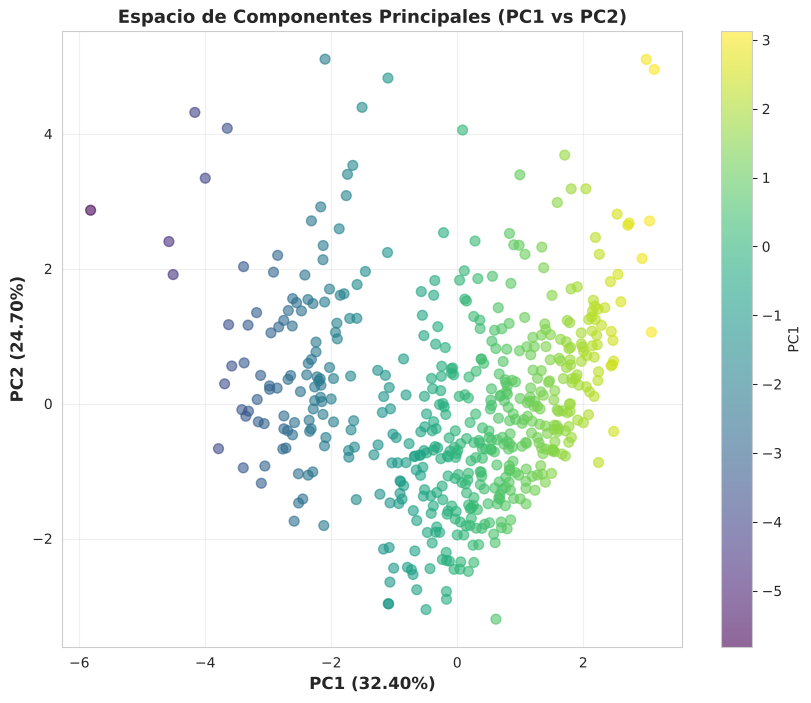

✓ Gráfica 2 generada: Espacios PCA (PC1 vs PC2)


In [13]:
# Visualización 2D de los datos transformados por PCA
fig, ax = plt.subplots(figsize=(10, 8))
scatter = ax.scatter(X_pca[:, 0], X_pca[:, 1], alpha=0.6, s=50, c=X_pca[:, 0], cmap='viridis')
ax.set_xlabel(f'PC1 ({pca.explained_variance_ratio_[0]:.2%})', fontsize=12, fontweight='bold')
ax.set_ylabel(f'PC2 ({pca.explained_variance_ratio_[1]:.2%})', fontsize=12, fontweight='bold')
ax.set_title('Espacio de Componentes Principales (PC1 vs PC2)', fontsize=13, fontweight='bold')
ax.grid(True, alpha=0.3)
plt.colorbar(scatter, ax=ax, label='PC1')
plt.show()

print("✓ Gráfica 2 generada: Espacios PCA (PC1 vs PC2)")

## SECCIÓN 4: Implementación y Optimización de Algoritmos de Clustering

**K-Means.** Probamos k de 2 a 10 y graficamos la inercia (WSS). El *codo* es el punto donde agregar más clusters deja de reducir mucho la dispersión interna.

In [14]:
# ALGORITMO 1: K-MEANS CON MÉTODO DEL CODO
print("\n" + "="*80)
print("ALGORITMO 1: K-MEANS (Método del Codo)")
print("="*80)

inercias = []
rango_k = range(2, 11)

for k in rango_k:
    kmeans_temp = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeans_temp.fit(X_escalado)  # Usar datos escalados, no PCA para el cálculo de inercia
    inercias.append(kmeans_temp.inertia_)

print(f"\nInercia para diferentes valores de k:")
for k, inercia in zip(rango_k, inercias):
    print(f"  k={k}: Inercia={inercia:.2f}")


ALGORITMO 1: K-MEANS (Método del Codo)



Inercia para diferentes valores de k:
  k=2: Inercia=3192.33
  k=3: Inercia=2616.11
  k=4: Inercia=2298.47
  k=5: Inercia=2013.61
  k=6: Inercia=1849.06
  k=7: Inercia=1719.21
  k=8: Inercia=1605.89
  k=9: Inercia=1511.46
  k=10: Inercia=1436.47


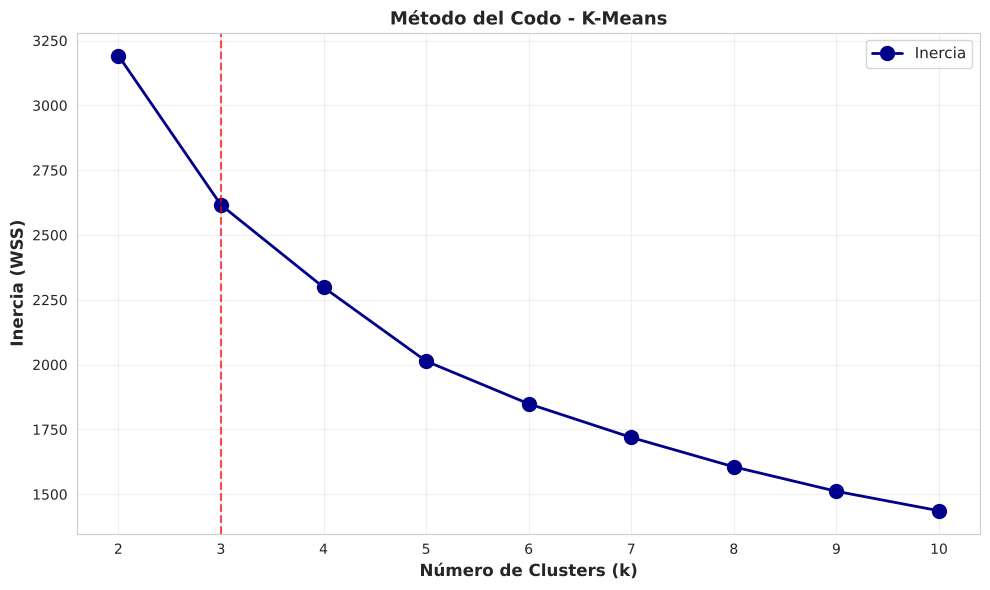

✓ Gráfica 3 generada: Método del Codo


In [15]:
# Gráfica 3: Método del Codo
fig, ax = plt.subplots(figsize=(10, 6))
ax.plot(rango_k, inercias, 'o-', linewidth=2, markersize=10, color='darkblue', label='Inercia')
ax.set_xlabel('Número de Clusters (k)', fontsize=12, fontweight='bold')
ax.set_ylabel('Inercia (WSS)', fontsize=12, fontweight='bold')
ax.set_title('Método del Codo - K-Means', fontsize=13, fontweight='bold')
ax.grid(True, alpha=0.3)
ax.legend(fontsize=11)

# Marcar el punto de codo sugerido (puede ajustarse)
# Típicamente entre k=3 y k=5
ax.axvline(x=3, color='red', linestyle='--', alpha=0.7, label='Codo sugerido')

plt.tight_layout()
plt.show()

print("✓ Gráfica 3 generada: Método del Codo")

In [16]:
# Seleccionar k óptimo basado en el codo
# Probar k=3, 4, 5 y evaluar con Silhouette
k_optimal_kmeans = 3  # Ajustar si es necesario según el gráfico

kmeans = KMeans(n_clusters=k_optimal_kmeans, random_state=42, n_init=10)
clusters_kmeans = kmeans.fit_predict(X_escalado)

# Silhouette Score
silhouette_kmeans = silhouette_score(X_escalado, clusters_kmeans)

print(f"\nK-Means con k={k_optimal_kmeans}:")
print(f"  Silhouette Score: {silhouette_kmeans:.4f}")
print(f"  Distribución de clusters:")
for i in range(k_optimal_kmeans):
    print(f"    Cluster {i}: {(clusters_kmeans == i).sum()} clientes")


K-Means con k=3:
  Silhouette Score: 0.2236
  Distribución de clusters:
    Cluster 0: 113 clientes
    Cluster 1: 191 clientes
    Cluster 2: 220 clientes


**DBSCAN.** Agrupa por densidad y marca como *ruido* los puntos aislados. Depende de `eps` (radio de vecindad) y `min_samples`; primero barremos `eps`, y después (celda siguiente a la selección) también `min_samples`.

### Justificación de k = 3
Comparamos Silhouette para distintos k. El máximo puramente numérico no es necesariamente la mejor decisión de negocio: elegimos **k = 3** por (1) el codo de la curva WSS, (2) tres segmentos con tamaños razonables y perfiles claramente distintos y accionables (ver Sección 6) y (3) que es la configuración replicada en RapidMiner. Si solo importara el Silhouette, k = 2 obtendría el valor más alto (0.32), pero dividiría a los clientes en solo dos grupos, con poca utilidad comercial.

In [17]:
# Silhouette, Davies-Bouldin y Calinski-Harabasz para distintos k
filas = []
for k in range(2, 8):
    lab = KMeans(n_clusters=k, random_state=42, n_init=10).fit_predict(X_escalado)
    filas.append({'k': k,
                  'Silhouette': silhouette_score(X_escalado, lab),
                  'Davies-Bouldin': davies_bouldin_score(X_escalado, lab),
                  'Calinski-Harabasz': calinski_harabasz_score(X_escalado, lab),
                  'Tamaño mín. cluster': np.bincount(lab).min()})
tabla_k = pd.DataFrame(filas)
print(tabla_k.round(4).to_string(index=False))
mejor_k = int(tabla_k.loc[tabla_k['Silhouette'].idxmax(), 'k'])
print(f"\nk con mayor Silhouette: {mejor_k}. Se mantiene k = {k_optimal_kmeans} por interpretabilidad de negocio y por consistencia con RapidMiner.")

 k  Silhouette  Davies-Bouldin  Calinski-Harabasz  Tamaño mín. cluster
 2      0.3181          1.4860           163.4631                  127
 3      0.2236          1.4734           156.9198                  113
 4      0.2307          1.3520           142.7958                   51
 5      0.2499          1.3367           140.3680                   33
 6      0.2144          1.3540           131.2710                   32
 7      0.2057          1.3852           123.9362                   31

k con mayor Silhouette: 2. Se mantiene k = 3 por interpretabilidad de negocio y por consistencia con RapidMiner.


In [18]:
# ALGORITMO 2: DBSCAN (Optimizar epsilon)
print("\n" + "="*80)
print("ALGORITMO 2: DBSCAN (Optimización de Epsilon)")
print("="*80)

# Probar diferentes valores de epsilon
epsilons = np.arange(0.3, 1.3, 0.1)
min_samples = 5

dbscan_results = []

for eps in epsilons:
    dbscan_temp = DBSCAN(eps=eps, min_samples=min_samples)
    clusters_temp = dbscan_temp.fit_predict(X_escalado)
    n_clusters = len(set(clusters_temp)) - (1 if -1 in clusters_temp else 0)
    n_noise = (clusters_temp == -1).sum()

    if n_clusters > 0 and n_clusters < len(X_escalado) - 1:
        silhouette_temp = silhouette_score(X_escalado, clusters_temp)
    else:
        silhouette_temp = -1

    dbscan_results.append({
        'eps': eps,
        'n_clusters': n_clusters,
        'n_noise': n_noise,
        'silhouette': silhouette_temp
    })

dbscan_df = pd.DataFrame(dbscan_results)
print("\nResultados DBSCAN para diferentes epsilon:")
print(dbscan_df.to_string(index=False))


ALGORITMO 2: DBSCAN (Optimización de Epsilon)

Resultados DBSCAN para diferentes epsilon:
 eps  n_clusters  n_noise  silhouette
 0.3           0      524   -1.000000
 0.4           0      524   -1.000000
 0.5           7      468   -0.309913
 0.6           6      413   -0.226949
 0.7           2      342   -0.083768
 0.8           2      306   -0.066912
 0.9           1      276    0.157710
 1.0           7      213   -0.204142
 1.1           5      183   -0.152229
 1.2           3      151    0.010526


In [19]:
# Seleccionar epsilon óptimo (mejor balance entre clusters y ruido)
# Preferir: silhouette positivo, no demasiado ruido, clusters interpretables
candidatos = dbscan_df[(dbscan_df['n_clusters'] >= 2) & (dbscan_df['n_noise'] < len(X_escalado) * 0.2)]
if len(candidatos) == 0:   # si ninguno cumple, el de menos ruido con al menos 2 clusters
    candidatos = dbscan_df[dbscan_df['n_clusters'] >= 2].sort_values('n_noise').head(1)
eps_optimal = round(candidatos.sort_values('silhouette', ascending=False).iloc[0]['eps'], 2)

dbscan = DBSCAN(eps=eps_optimal, min_samples=min_samples)
clusters_dbscan = dbscan.fit_predict(X_escalado)
silhouette_dbscan = silhouette_score(X_escalado, clusters_dbscan)

print(f"\nDBSCAN con eps={eps_optimal:.2f}, min_samples={min_samples}:")
print(f"  Silhouette Score: {silhouette_dbscan:.4f}")
print(f"  Número de clusters: {len(set(clusters_dbscan)) - (1 if -1 in clusters_dbscan else 0)}")
print(f"  Puntos clasificados como ruido: {(clusters_dbscan == -1).sum()}")
print(f"  Distribución de clusters:")
for i in sorted(set(clusters_dbscan)):
    if i != -1:
        print(f"    Cluster {i}: {(clusters_dbscan == i).sum()} clientes")
    else:
        print(f"    Ruido: {(clusters_dbscan == i).sum()} clientes")


DBSCAN con eps=1.20, min_samples=5:
  Silhouette Score: 0.0105
  Número de clusters: 3
  Puntos clasificados como ruido: 151
  Distribución de clusters:
    Ruido: 151 clientes
    Cluster 0: 358 clientes
    Cluster 1: 6 clientes
    Cluster 2: 9 clientes


**Clustering jerárquico (aglomerativo).** Probamos los enlaces ward, complete y average. Ojo: un Silhouette muy alto con `average` suele ser engañoso si crea clusters de 1–4 clientes (clusters degenerados); se reporta ward como referencia válida.

**Búsqueda adicional sobre `min_samples`.** Para ser exhaustivos, barremos también `min_samples` y mostramos la mejor configuración por Silhouette (calculado sin contar el ruido) con ≤ 20 % de ruido. Si ninguna mejora de forma clara, confirma que el problema es la estructura de los datos y no el ajuste de parámetros.

In [20]:
# Barrido conjunto de eps x min_samples
res = []
for ms in [3, 5, 8, 10, 15]:
    for eps in np.arange(0.3, 1.31, 0.1):
        lab = DBSCAN(eps=eps, min_samples=ms).fit_predict(X_escalado)
        ncl = len(set(lab)) - (1 if -1 in lab else 0)
        ruido = (lab == -1).mean()
        mask = lab != -1
        sil = silhouette_score(X_escalado[mask], lab[mask]) if ncl >= 2 and mask.sum() > ncl else np.nan
        res.append({'min_samples': ms, 'eps': round(eps, 2), 'clusters': ncl, 'ruido_%': round(ruido*100, 1), 'silhouette_sin_ruido': sil})
grid = pd.DataFrame(res)
ok = grid[(grid['clusters'] >= 2) & (grid['ruido_%'] <= 20)].sort_values('silhouette_sin_ruido', ascending=False)
print("Mejores configuraciones (>=2 clusters y <=20% de ruido):")
print(ok.head(8).round(3).to_string(index=False) if len(ok) else "Ninguna configuración cumple (>=2 clusters y <=20% de ruido).")
print(f"\nConfiguración usada en la comparación: eps={eps_optimal}, min_samples={min_samples} "
      f"(Silhouette {silhouette_dbscan:.3f}, {(clusters_dbscan == -1).mean():.1%} de ruido).")
print("Conclusión: ninguna combinación produce clusters densos bien separados con poco ruido; DBSCAN no es adecuado para estos datos.")

Mejores configuraciones (>=2 clusters y <=20% de ruido):
 min_samples  eps  clusters  ruido_%  silhouette_sin_ruido
           3  1.3         6     16.8                 0.072
           3  1.2        10     20.0                -0.074

Configuración usada en la comparación: eps=1.2, min_samples=5 (Silhouette 0.011, 28.8% de ruido).
Conclusión: ninguna combinación produce clusters densos bien separados con poco ruido; DBSCAN no es adecuado para estos datos.


In [21]:
# ALGORITMO 3: HIERARCHICAL CLUSTERING (Aglomerativo)
print("\n" + "="*80)
print("ALGORITMO 3: Hierarchical Clustering (Aglomerativo)")
print("="*80)

# Probar diferentes linkages
linkages = ['ward', 'complete', 'average']
n_clusters_hier = k_optimal_kmeans  # Usar mismo k que K-Means para comparación

hier_results = []

for linkage in linkages:
    hier_temp = AgglomerativeClustering(n_clusters=n_clusters_hier, linkage=linkage)
    clusters_temp = hier_temp.fit_predict(X_escalado)
    silhouette_temp = silhouette_score(X_escalado, clusters_temp)

    hier_results.append({
        'linkage': linkage,
        'silhouette': silhouette_temp,
        'cluster_mas_chico': np.bincount(clusters_temp).min()
    })

hier_df = pd.DataFrame(hier_results)
print(f"\nResultados Hierarchical Clustering (n_clusters={n_clusters_hier}):")
print(hier_df.to_string(index=False))

# Seleccionar mejor linkage SOLO entre soluciones sin grupos diminutos (>= 5% de clientes).
# 'complete' y 'average' dan silueta alta porque dejan 1-2 clientes atípicos solos y el resto en un grupo,
# lo cual no es una segmentación útil.
validos = hier_df[hier_df['cluster_mas_chico'] >= 0.05 * len(X_escalado)]
best_linkage = (validos if len(validos) else hier_df).sort_values('silhouette', ascending=False).iloc[0]['linkage']
hierarchical = AgglomerativeClustering(n_clusters=n_clusters_hier, linkage=best_linkage)
clusters_hierarchical = hierarchical.fit_predict(X_escalado)
silhouette_hierarchical = silhouette_score(X_escalado, clusters_hierarchical)

print(f"\nHierarchical Clustering con linkage='{best_linkage}':")
print(f"  Silhouette Score: {silhouette_hierarchical:.4f}")
print(f"  Distribución de clusters:")
for i in range(n_clusters_hier):
    print(f"    Cluster {i}: {(clusters_hierarchical == i).sum()} clientes")


ALGORITMO 3: Hierarchical Clustering (Aglomerativo)

Resultados Hierarchical Clustering (n_clusters=3):
 linkage  silhouette  cluster_mas_chico
    ward    0.176916                 97
complete    0.174788                 12
 average    0.473336                  1

Hierarchical Clustering con linkage='ward':
  Silhouette Score: 0.1769
  Distribución de clusters:
    Cluster 0: 309 clientes
    Cluster 1: 118 clientes
    Cluster 2: 97 clientes


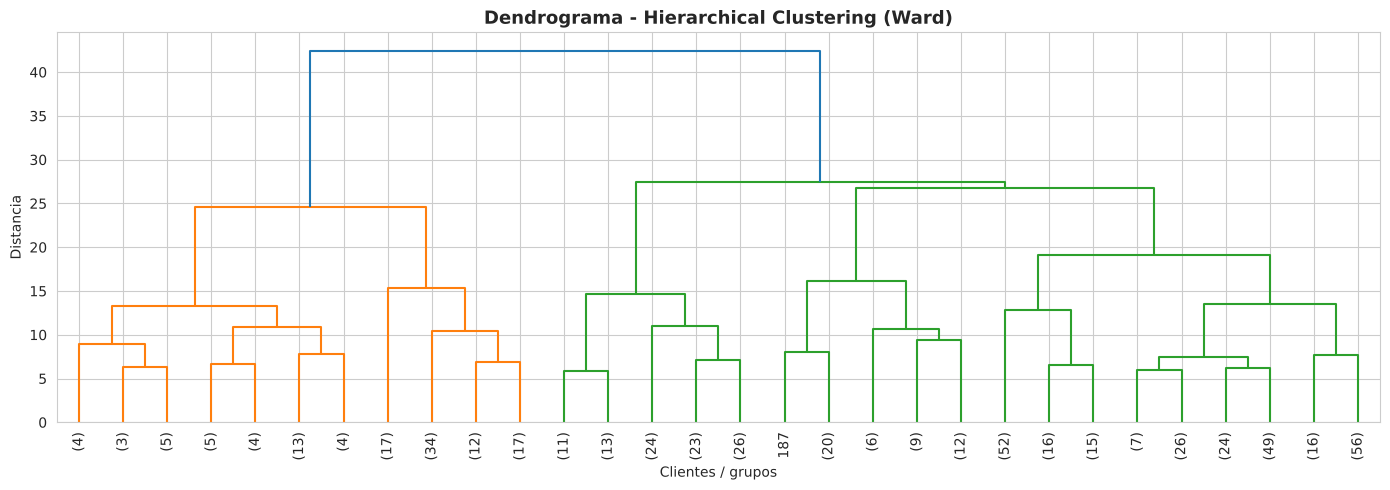

In [22]:
# Dendrograma (Ward) del agrupamiento jerárquico
from scipy.cluster.hierarchy import linkage as sch_linkage, dendrogram
Z = sch_linkage(X_escalado, method='ward')
plt.figure(figsize=(14, 5))
dendrogram(Z, truncate_mode='lastp', p=30, leaf_rotation=90)
plt.title('Dendrograma - Hierarchical Clustering (Ward)', fontsize=13, fontweight='bold')
plt.xlabel('Clientes / grupos'); plt.ylabel('Distancia')
plt.tight_layout(); plt.show()

## SECCIÓN 5: Cuadro Comparativo de Modelos (Silhouette Score)

In [23]:
# Comparación de los tres algoritmos
print("\n" + "="*80)
print("COMPARACIÓN DE ALGORITMOS DE CLUSTERING")
print("="*80)

comparacion = pd.DataFrame({
    'Algoritmo': ['K-Means', 'DBSCAN', 'Hierarchical Clustering'],
    'Número de Clusters': [
        k_optimal_kmeans,
        len(set(clusters_dbscan)) - (1 if -1 in clusters_dbscan else 0),
        n_clusters_hier
    ],
    'Silhouette Score': [
        silhouette_kmeans,
        silhouette_dbscan,
        silhouette_hierarchical
    ],
    # Davies-Bouldin: menor es mejor | Calinski-Harabasz: mayor es mejor
    'Davies-Bouldin': [
        davies_bouldin_score(X_escalado, clusters_kmeans),
        davies_bouldin_score(X_escalado, clusters_dbscan),
        davies_bouldin_score(X_escalado, clusters_hierarchical)
    ],
    'Calinski-Harabasz': [
        calinski_harabasz_score(X_escalado, clusters_kmeans),
        calinski_harabasz_score(X_escalado, clusters_dbscan),
        calinski_harabasz_score(X_escalado, clusters_hierarchical)
    ],
    'Ruido (%)': [0.0, (clusters_dbscan == -1).mean() * 100, 0.0]
})

print("\n")
print(comparacion.to_string(index=False))

# Identificar mejor algoritmo
mejor_algoritmo = comparacion.loc[comparacion['Silhouette Score'].idxmax(), 'Algoritmo']
print(f"\n✓ Mejor algoritmo según Silhouette Score: {mejor_algoritmo}")
print(f"✓ Mejor según Davies-Bouldin (menor): {comparacion.loc[comparacion['Davies-Bouldin'].idxmin(), 'Algoritmo']}")
print(f"✓ Mejor según Calinski-Harabasz (mayor): {comparacion.loc[comparacion['Calinski-Harabasz'].idxmax(), 'Algoritmo']}")
print(f"\nNota: DBSCAN obtuvo el peor Silhouette ({silhouette_dbscan:.2f}) y dejó {(clusters_dbscan == -1).mean():.0%} de los clientes como ruido: "
      "los clientes forman una masa continua, sin zonas de densidad bien separadas, por lo que no sirve para segmentar.")
print("K-Means gana en Silhouette, Davies-Bouldin y Calinski-Harabasz.")


COMPARACIÓN DE ALGORITMOS DE CLUSTERING


              Algoritmo  Número de Clusters  Silhouette Score  Davies-Bouldin  Calinski-Harabasz  Ruido (%)
                K-Means                   3          0.223634        1.473366         156.919821   0.000000
                 DBSCAN                   3          0.010526        1.916525          32.524358  28.816794
Hierarchical Clustering                   3          0.176916        1.608171         114.158738   0.000000

✓ Mejor algoritmo según Silhouette Score: K-Means
✓ Mejor según Davies-Bouldin (menor): K-Means
✓ Mejor según Calinski-Harabasz (mayor): K-Means

Nota: DBSCAN obtuvo el peor Silhouette (0.01) y dejó 29% de los clientes como ruido: los clientes forman una masa continua, sin zonas de densidad bien separadas, por lo que no sirve para segmentar.
K-Means gana en Silhouette, Davies-Bouldin y Calinski-Harabasz.


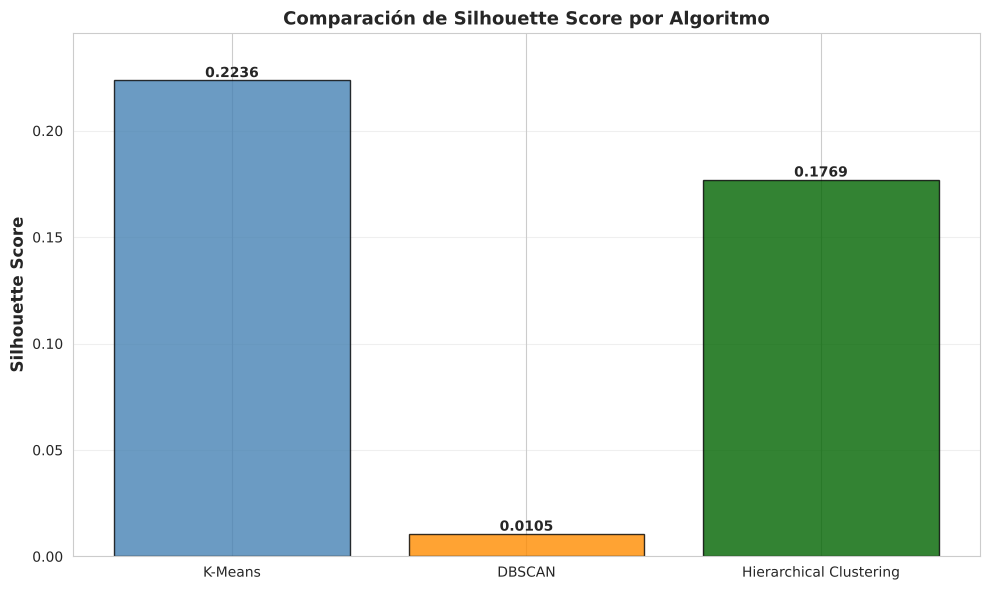

✓ Gráfica 4 generada: Comparación Silhouette Score


In [24]:
# Gráfica 4: Comparación de Silhouette Scores
fig, ax = plt.subplots(figsize=(10, 6))
bars = ax.bar(comparacion['Algoritmo'], comparacion['Silhouette Score'],
               color=['steelblue', 'darkorange', 'darkgreen'], alpha=0.8, edgecolor='black')
ax.set_ylabel('Silhouette Score', fontsize=12, fontweight='bold')
ax.set_title('Comparación de Silhouette Score por Algoritmo', fontsize=13, fontweight='bold')
ax.grid(True, axis='y', alpha=0.3)
ax.set_ylim([0, max(comparacion['Silhouette Score']) * 1.1])

# Añadir valores en las barras
for bar in bars:
    height = bar.get_height()
    ax.text(bar.get_x() + bar.get_width()/2., height,
            f'{height:.4f}',
            ha='center', va='bottom', fontweight='bold')

plt.tight_layout()
plt.show()

print("✓ Gráfica 4 generada: Comparación Silhouette Score")

## SECCIÓN 6: Conclusiones e Interpretación Comercial de Clusters

**Interpretación comercial.** Elegimos K-Means (mejor métrica y más interpretable), calculamos el promedio de cada variable por cluster en unidades originales y le damos nombre de negocio a cada segmento.

In [25]:
# Seleccionar el mejor modelo para análisis final
# Usar K-Means como estándar (más interpretable)
clusters_final = clusters_kmeans
algoritmo_final = 'K-Means'

# Agregar clusters a la tabla de clientes
cliente_agg['Cluster'] = clusters_final

# Nombre de cada segmento según sus características (no según el número de etiqueta)
medias = cliente_agg.groupby('Cluster')[variables_clustering].mean()
leales = medias['Gasto_Total'].idxmax()
ticket_alto = medias.drop(index=leales)['Ticket_Promedio'].idxmax()
jovenes = [c for c in medias.index if c not in (leales, ticket_alto)][0]
nombres = {leales: 'Leales de alto valor', jovenes: 'Jóvenes de bajo gasto', ticket_alto: 'Ticket alto'}
cliente_agg['Segmento'] = cliente_agg['Cluster'].map(nombres)

print(f"\nAnálisis del modelo ganador: {algoritmo_final}")
print("="*80)
print(f"Número de clusters: {k_optimal_kmeans}")
print(f"Silhouette Score: {silhouette_kmeans:.4f}")


Análisis del modelo ganador: K-Means
Número de clusters: 3
Silhouette Score: 0.2236


In [26]:
# Análisis descriptivo de cada cluster
print("\nCARACTERÍSTICAS DE CADA CLUSTER:")
print("="*80)

for cluster_id in sorted(cliente_agg['Cluster'].unique()):
    cluster_data = cliente_agg[cliente_agg['Cluster'] == cluster_id]
    print(f"\n📊 CLUSTER {cluster_id} · {nombres[cluster_id]}")
    print(f"   Número de clientes: {len(cluster_data)}")
    print(f"   Porcentaje: {len(cluster_data)/len(cliente_agg)*100:.1f}%")
    print(f"\n   Estadísticas:")
    print(f"   Gasto Total (promedio): ${cluster_data['Gasto_Total'].mean():.2f}")
    print(f"   Ticket Promedio: ${cluster_data['Ticket_Promedio'].mean():.2f}")
    print(f"   Líneas de venta (promedio): {cluster_data['Num_Transacciones'].mean():.1f}")
    print(f"   Antiguedad (promedio): {cluster_data['Antiguedad'].mean():.1f} años")
    print(f"   Edad (promedio): {cluster_data['Edad'].mean():.1f} años")


CARACTERÍSTICAS DE CADA CLUSTER:

📊 CLUSTER 0 · Ticket alto
   Número de clientes: 113
   Porcentaje: 21.6%

   Estadísticas:
   Gasto Total (promedio): $5130.17
   Ticket Promedio: $952.95
   Líneas de venta (promedio): 6.9
   Antiguedad (promedio): 5.3 años
   Edad (promedio): 34.1 años

📊 CLUSTER 1 · Leales de alto valor
   Número de clientes: 191
   Porcentaje: 36.5%

   Estadísticas:
   Gasto Total (promedio): $14360.11
   Ticket Promedio: $66.61
   Líneas de venta (promedio): 266.2
   Antiguedad (promedio): 9.4 años
   Edad (promedio): 38.1 años

📊 CLUSTER 2 · Jóvenes de bajo gasto
   Número de clientes: 220
   Porcentaje: 42.0%

   Estadísticas:
   Gasto Total (promedio): $1854.53
   Ticket Promedio: $62.00
   Líneas de venta (promedio): 33.0
   Antiguedad (promedio): 3.4 años
   Edad (promedio): 30.9 años


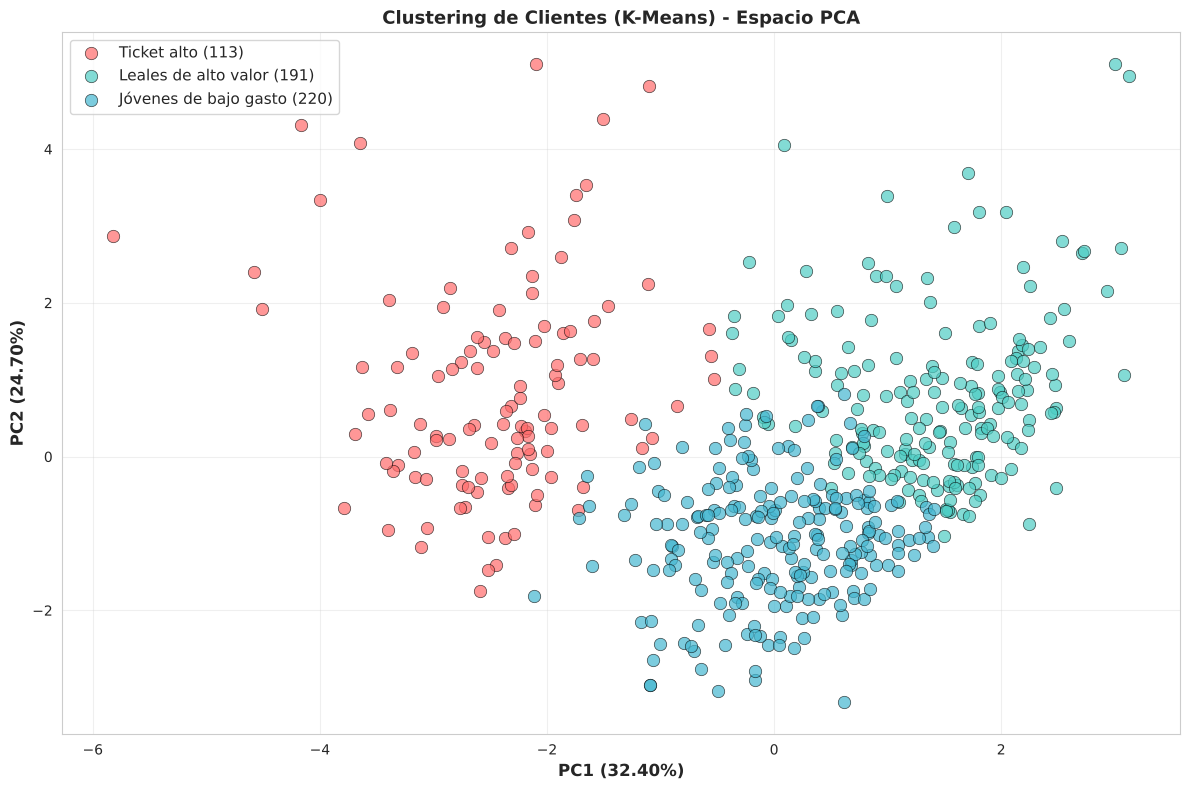

✓ Visualización final generada


In [27]:
# Visualización final: Clusters en espacio PCA
fig, ax = plt.subplots(figsize=(12, 8))

# Crear colores para cada cluster
colores = ['#FF6B6B', '#4ECDC4', '#45B7D1', '#FFA07A', '#98D8C8']

for cluster_id in sorted(set(clusters_kmeans)):
    indices = np.where(clusters_kmeans == cluster_id)[0]
    ax.scatter(X_pca[indices, 0], X_pca[indices, 1],
              label=f'{nombres[cluster_id]} ({len(indices)})',
              s=80, alpha=0.7,
              color=colores[cluster_id % len(colores)],
              edgecolors='black', linewidth=0.5)

ax.set_xlabel(f'PC1 ({pca.explained_variance_ratio_[0]:.2%})', fontsize=12, fontweight='bold')
ax.set_ylabel(f'PC2 ({pca.explained_variance_ratio_[1]:.2%})', fontsize=12, fontweight='bold')
ax.set_title(f'Clustering de Clientes ({algoritmo_final}) - Espacio PCA', fontsize=13, fontweight='bold')
ax.legend(fontsize=11, loc='best')
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

print("✓ Visualización final generada")

In [28]:
# CONCLUSIONES FINALES
print("\n" + "="*80)
print("CONCLUSIONES")
print("="*80)

print(f"""
\n1. MODELO SELECCIONADO: {algoritmo_final}
   - Silhouette Score: {silhouette_kmeans:.4f}
   - Número de clusters: {k_optimal_kmeans}
   - Ganó en Silhouette, Davies-Bouldin y Calinski-Harabasz frente a DBSCAN y Jerárquico (Sección 5).

2. SEGMENTACIÓN DE CLIENTES:
   Se identificaron {k_optimal_kmeans} segmentos principales de clientes con
   características comerciales distintas. Cada segmento tiene patrones de compra,
   gasto y antigüedad específicos que pueden ser aprovechados para estrategias
   de marketing personalizadas.

3. REDUCCIÓN DIMENSIONAL (PCA):
   Se redujeron {len(variables_clustering)} dimensiones originales a {n_componentes}
   componentes principales, explicando el {pca.explained_variance_ratio_.sum():.1%}
   de la varianza total. Esto permite interpretación visual y reduce complejidad computacional.

4. RECOMENDACIONES COMERCIALES:
   - Leales de alto valor ({(cliente_agg['Segmento'] == 'Leales de alto valor').sum()} clientes): mayor gasto, más líneas de compra y mayor antigüedad.
     Estrategia de lealtad y retención, beneficios por volumen.
   - Jóvenes de bajo gasto ({(cliente_agg['Segmento'] == 'Jóvenes de bajo gasto').sum()} clientes): gasto, antigüedad y edad por debajo del promedio.
     Campañas de activación y promociones de entrada.
   - Ticket alto ({(cliente_agg['Segmento'] == 'Ticket alto').sum()} clientes): pocas compras, pero de precio y monto muy altos.
     Promociones premium y recordatorios de recompra.

5. PRÓXIMOS PASOS:
   - Replicado en RapidMiner (datos limpios de Python y desde el archivo original): mismos centroides
   - Crear campañas específicas por segmento
   - Monitorear cambios en la composición de clusters
""")

print("\n" + "="*80)
print("FIN DEL ANÁLISIS")
print("="*80)


CONCLUSIONES


1. MODELO SELECCIONADO: K-Means
   - Silhouette Score: 0.2236
   - Número de clusters: 3
   - Ganó en Silhouette, Davies-Bouldin y Calinski-Harabasz frente a DBSCAN y Jerárquico (Sección 5).

2. SEGMENTACIÓN DE CLIENTES:
   Se identificaron 3 segmentos principales de clientes con
   características comerciales distintas. Cada segmento tiene patrones de compra,
   gasto y antigüedad específicos que pueden ser aprovechados para estrategias
   de marketing personalizadas.

3. REDUCCIÓN DIMENSIONAL (PCA):
   Se redujeron 8 dimensiones originales a 3
   componentes principales, explicando el 74.8%
   de la varianza total. Esto permite interpretación visual y reduce complejidad computacional.

4. RECOMENDACIONES COMERCIALES:
   - Leales de alto valor (191 clientes): mayor gasto, más líneas de compra y mayor antigüedad.
     Estrategia de lealtad y retención, beneficios por volumen.
   - Jóvenes de bajo gasto (220 clientes): gasto, antigüedad y edad por debajo del promedio.
  

## ANEXO: Pruebas de robustez
Dos verificaciones sobre decisiones del análisis: (A) qué pasa si K-Means se entrena sobre los componentes PCA en lugar de las 8 variables escaladas y (B) qué pasa si `Num_Transacciones` cuenta transacciones únicas en vez de líneas de venta.

In [29]:
# A) K-Means sobre el espacio PCA vs sobre las 8 variables escaladas
from sklearn.metrics import adjusted_rand_score
km_pca = KMeans(n_clusters=k_optimal_kmeans, random_state=42, n_init=10).fit(X_pca)
ari = adjusted_rand_score(clusters_kmeans, km_pca.labels_)
print(f"Varianza explicada por {n_componentes} componentes: {pca.explained_variance_ratio_.sum():.1%}")
print(f"Tamaños de los clusters sobre PCA: {np.bincount(km_pca.labels_)}")
print(f"Concordancia (Adjusted Rand Index) K-Means en PCA vs en 8 variables: {ari:.3f}  (1 = idénticos)")
print("-> Entrenar sobre PCA produce prácticamente los mismos segmentos.")

Varianza explicada por 3 componentes: 74.8%
Tamaños de los clusters sobre PCA: [117 196 211]
Concordancia (Adjusted Rand Index) K-Means en PCA vs en 8 variables: 0.909  (1 = idénticos)
-> Entrenar sobre PCA produce prácticamente los mismos segmentos.


In [30]:
# B) Sensibilidad: contar transacciones únicas (columna 'Transaccion') en vez de líneas de venta
t = df.groupby(['Clave_Cliente', 'Transaccion']).agg(imp=('Importe', 'sum'), unid=('Cantidad', 'sum')).reset_index()
tg = t.groupby('Clave_Cliente')
gc = df.groupby('Clave_Cliente')
alt = pd.DataFrame({
    'Gasto_Total': tg['imp'].sum(), 'Ticket_Promedio': tg['imp'].mean(), 'Num_Transacciones': tg['imp'].count(),
    'Cantidad_Promedio': tg['unid'].mean(), 'Precio_Promedio': gc['Precio'].mean(),
    'Antiguedad': gc['Antiguedad'].first(), 'Edad': gc['Edad'].first(), 'Num_Hijos': gc['No._Hijos'].first(),
}).loc[cliente_agg['Clave_Cliente']][variables_clustering]

alt[variables_sesgadas] = np.log1p(alt[variables_sesgadas])
alt_esc = StandardScaler().fit_transform(alt)
lab_alt = KMeans(n_clusters=k_optimal_kmeans, random_state=42, n_init=10).fit_predict(alt_esc)

print(f"Promedio por cliente: {cliente_agg['Num_Transacciones'].mean():.0f} líneas de venta vs {np.expm1(alt['Num_Transacciones']).mean():.0f} transacciones únicas")
print(f"Tamaños con transacciones únicas: {np.bincount(lab_alt)} | Silhouette = {silhouette_score(alt_esc, lab_alt):.4f}")
print(f"Concordancia con la segmentación principal (ARI): {adjusted_rand_score(clusters_kmeans, lab_alt):.3f}")
print("-> Los segmentos son similares; la conclusión no depende de esta definición.")

Promedio por cliente: 112 líneas de venta vs 22 transacciones únicas
Tamaños con transacciones únicas: [214 197 113] | Silhouette = 0.2197
Concordancia con la segmentación principal (ARI): 0.706
-> Los segmentos son similares; la conclusión no depende de esta definición.


## SECCIÓN 7: Exportación del CSV para RapidMiner

In [31]:
# Agregar los clusters de los tres algoritmos a la tabla de clientes
export = cliente_agg[['Clave_Cliente'] + variables_clustering].copy()
export['Cluster_KMeans'] = clusters_kmeans
export['Cluster_DBSCAN'] = clusters_dbscan          # -1 = ruido
export['Cluster_Jerarquico'] = clusters_hierarchical

export_esc = pd.DataFrame(X_escalado, columns=variables_clustering)
export_esc.insert(0, 'Clave_Cliente', cliente_agg['Clave_Cliente'].values)
export_esc['Cluster_KMeans'] = clusters_kmeans

# sep=',' y decimal='.' para que RapidMiner lo lea sin problemas; utf-8 para los acentos
export_esc.to_csv('clientes_rapidminer_escalado.csv', index=False, encoding='utf-8')
print('Archivos generados:', export.shape, export_esc.shape)

# Descargar a la computadora (Google Colab). En Jupyter local los archivos quedan en la carpeta del notebook.
try:
    from google.colab import files
    files.download('clientes_rapidminer_escalado.csv')
except ImportError:
    import os
    print('No es Colab; archivos guardados en:', os.getcwd())

Archivos generados: (524, 12) (524, 10)
No es Colab; archivos guardados en: /tmp/run
